---
title: "Лекція 6. Ідентифікація, калібрування та достовірність моделей складних систем"
description: "Математичне моделювання складних систем | PhD F3 «Комп'ютерні науки» | КрНУ ім. М. Остроградського"
author: "&copy; [Valeriy Sydorenko](https://www.linkedin.com/in/valeriy-sydorenko-6782279a/), 2026"
date: today
jupyter: python3
bibliography: mmss-references.bib
format:
  html:
    code-fold: show
    code-summary: "Показати код"
    code-overflow: wrap
    toc: true
    toc-depth: 4
    toc-location: right
    number-sections: false
    embed-resources: true
    smooth-scroll: true
---

::: callout-note
## Примітка
Лекція охоплює:
- *Тему 8. Ідентифікація та калібрування моделей* -- 1 год;
- *Тему 9. Верифікація та валідація моделей (Verification & Validation, V&V)* -- 1 год.

Наскрізна логіка:
$$
\text{model architecture}\rightarrow\text{identification / calibration}\rightarrow
\text{verification}\rightarrow\text{validation}\rightarrow\text{model credibility}.
$$

Ключова теза:
$$
\boxed{\text{calibrated model}\neq\text{validated model}\neq\text{universally true model}}
$$
:::

# Вступ
Перші п'ять лекцій відповідали переважно на питання: *яку модель складної системи ми будуємо і яку поведінку вона здатна породжувати?*

Після вибору model architecture виникає інша група питань: які parameters відповідають observations; чи можна їх однозначно визначити; чи правильно реалізовано equations та algorithms; наскільки numerical solution точний; чи відповідає model реальній системі достатньо добре для конкретного intended use?

Це перехід від *model construction* до *model credibility* [@oberkampfRoy2010].

# Тема 8. Ідентифікація та калібрування моделей

## 1. Де ми знаходимося в циклі моделювання
Нехай маємо model class
$$
\mathcal{M}=\{M(\theta):\theta\in\Theta\}.
$$
System boundary, state variables, structure та computational representation вже визначені, але
$$
\theta=(\theta_1,\ldots,\theta_p)
$$
може бути невідомим. Observations стають джерелом інформації про $\theta$.

## 2. Пряма та обернена задачі
*Пряма задача (direct problem)*:
$$
\theta\rightarrow\hat{\mathbf y}(\theta).
$$
*Обернена задача (inverse problem)*:
$$
\mathbf y^{obs}+M\rightarrow\hat\theta.
$$
У загальному вигляді
$$
\mathbf y^{obs}=\mathcal H(M(\theta))+\varepsilon,
$$
де $\mathcal H$ -- observation operator. Ідентифікація є inference problem від data до невідомих характеристик model [@gubarev2019].

## 3. Параметрична та структурна ідентифікація
*Параметрична ідентифікація (parametric identification)*: structure $M(\theta)$ відома, шукаємо $\theta$.

*Структурна ідентифікація (structural identification)*: порівнюємо можливі structures
$$
M_1,M_2,\ldots,M_K.
$$

Важливо:
$$
\text{structural identification}\neq\text{structural identifiability}.
$$
Перше -- вибір structure; друге -- однозначність відновлення parameters для заданої structure.

## 4. Калібрування (calibration)
Калібрування -- оцінювання невідомих model parameters шляхом узгодження outputs із calibration data:
$$
\hat\theta=\arg\min_{\theta\in\Theta}J(\theta),
$$
$$
J(\theta)=d(\mathbf y^{obs},\mathbf y^{model}(\theta)).
$$
У ЛР5 ми використовували
$$
J(\theta)=\sum_{i=1}^n[y_i-\hat y_i(\theta)]^2.
$$
Criterion визначає, що саме означає «краще узгодження».

## 5. Loss function -- частина моделі дослідження
Якщо
$$
\varepsilon_i\sim\mathcal N(0,\sigma^2)
$$
незалежні та мають однакову variance, minimization SSE узгоджується з maximum likelihood estimation. За heteroscedasticity, різної reliability, outliers або різних scales може бути доцільним
$$
J_w(\theta)=\sum_i w_i[y_i-\hat y_i(\theta)]^2.
$$
Loss function -- не технічний default, а формалізація того, які discrepancies вважаємо важливими.

## 6. Ідентифікованість (identifiability)
Якщо
$$
\mathbf y(\theta_1)=\mathbf y(\theta_2),\qquad \theta_1\neq\theta_2,
$$
observations не дозволяють однозначно відрізнити parameter sets.

*Структурна ідентифікованість (structural identifiability)* стосується ideal observations. *Практична ідентифікованість (practical identifiability)* -- finite, noisy, incomplete data. У ЛР5 early logistic-growth data містили мало інформації про $K$.

## 7. Геометрія inverse problem
Loss surface $J(\theta_1,\theta_2)$ може мати:
- isolated basin -- parameters strongly constrained;
- ridge/valley -- parameter compensation;
- multiple minima -- залежність від initial guess.

Тому
$$
\text{optimizer convergence}\not\Rightarrow\text{identifiability}.
$$

## 8. Простий приклад компенсації параметрів
Нехай
$$
y=abx,\qquad x=1,\qquad y^{obs}=6.
$$
Усі pairs з
$$
ab=6
$$
дають perfect fit. Data визначають combination $c=ab$, але не $a$ та $b$ окремо.

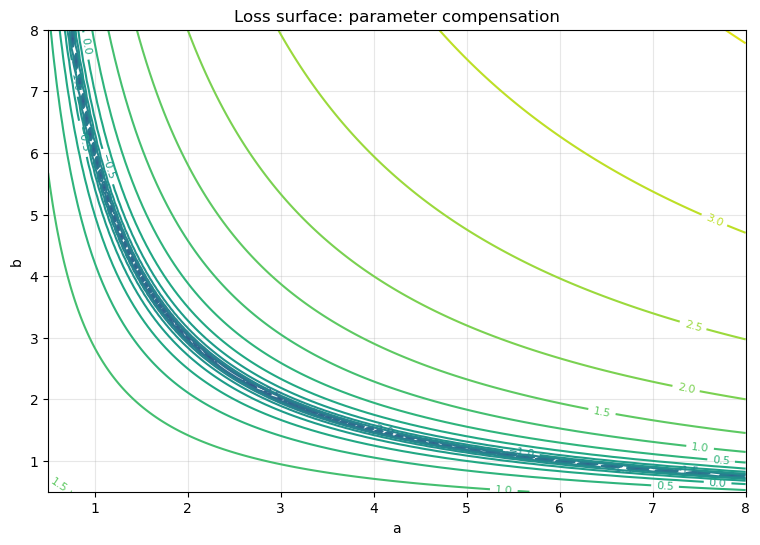

In [1]:
import numpy as np
import matplotlib.pyplot as plt

a = np.linspace(0.5, 8.0, 200)
b = np.linspace(0.5, 8.0, 200)
A, B = np.meshgrid(a, b)

Y_OBS = 6.0
J = (Y_OBS - A * B) ** 2

plt.figure(figsize=(9, 6))
contours = plt.contour(A, B, np.log10(J + 1e-6), levels=20)
plt.clabel(contours, inline=True, fontsize=8)
plt.xlabel("a")
plt.ylabel("b")
plt.title("Loss surface: parameter compensation")
plt.grid(alpha=0.3)
plt.show()

Minimum витягнутий уздовж $ab=6$. Жодний «кращий optimizer» не створить інформацію, якої немає в observations.

## 9. Calibration data та information content
Identifiability залежить не лише від model:
$$
\text{identifiability}=I(M,\mathcal H,u(t),t_i,\text{noise}).
$$
Важливо, що вимірюємо, коли, як часто, за яких inputs і з якою precision. Design of experiment може покращувати identifiability.

## 10. Model discrepancy
Корисно концептуально записати
$$
y^{obs}=y^{model}(\theta)+\delta+\varepsilon,
$$
де $\varepsilon$ -- observation error, а $\delta$ -- model discrepancy.

Якщо $\delta$ ігнорується, calibration може змінювати $\theta$, щоб parameters компенсували structural deficiency. Тоді calibrated parameters можуть бути *effective parameters*.

## 11. Over-calibration
Для більш гнучкої model часто
$$
J_{M_2}^{min}\le J_{M_1}^{min}.
$$
Але додаткові parameters можуть fit noise, mask discrepancy, створювати non-identifiability та погіршувати extrapolation. Calibration error -- лише один компонент evidence.

## 12. Що повинно залишитися після calibration
Результат -- не лише $\hat\theta$. Потрібно зберігати calibration dataset, preprocessing, observation model, loss, bounds, starts, optimizer, solver tolerances, residual diagnostics, identifiability evidence та limitations. Саме тому ЛР5 формує *Calibration Specification v0.5*.

# Тема 9. Верифікація та валідація моделей (Verification & Validation, V&V)

## 13. Центральне питання model credibility
Після calibration маємо
$$
\hat M=M(\hat\theta).
$$
Потрібно встановити, наскільки результатам цієї model можна довіряти для конкретної мети [@oberkampfRoy2010].

Корисна інтуїція:
- verification -- чи правильно розв'язуємо equations;
- validation -- чи equations достатньо адекватні reality для intended use.

## 14. Ієрархія помилок
$$
\text{reality}\rightarrow\text{conceptual model}\rightarrow\text{mathematical model}
\rightarrow\text{numerical model}\rightarrow\text{software}\rightarrow\text{computed result}.
$$

```{mermaid}
%%{init: {'theme': 'base', 'themeVariables': {'fontSize':'18px','fontFamily':'Trebuchet MS, Verdana, Arial, sans-serif','primaryColor':'#E8F3FF','primaryBorderColor':'#3478A8','secondaryColor':'#FFF0C9','tertiaryColor':'#E7F6EC','lineColor':'#536878'}}}%%
flowchart LR
 A("Real<br/>system") --> B("Conceptual<br/>model")
 B --> C("Mathematical<br/>model")
 C --> D("Numerical<br/>method")
 D --> E("Software<br/>implementation")
 E --> F("Computed<br/>result")
```

Не можна всі discrepancies називати «похибкою моделі».

## 15. Верифікація (verification)
Verification стосується відповідності computational implementation математичній постановці:
$$
\text{mathematical model}\stackrel{?}{=}\text{implemented computational model}.
$$
Питання: equations, coding errors, initial/boundary conditions, numerical algorithm, accuracy of solution.

## 16. Code verification і solution verification
*Code verification*: чи правильно code реалізує formulation? Методи: unit tests, analytical benchmarks, manufactured solutions, independent implementation, conservation checks.

*Solution verification*: наскільки numerical approximation конкретного simulation case близька до exact solution mathematical model? Досліджуємо discretization error, iterative error, tolerances, convergence with resolution [@oberkampfRoy2010].

## 17. Простий приклад solution verification
Розглянемо
$$
\frac{dx}{dt}=-x,\qquad x(0)=1,
$$
з exact solution
$$
x(t)=e^{-t}.
$$
Explicit Euler:
$$
x_{n+1}=x_n-hx_n.
$$

In [2]:
def euler_decay(h, T=2.0):
    n_steps = int(round(T / h))
    x = 1.0
    for _ in range(n_steps):
        x = x - h * x
    return x

T = 2.0
exact = np.exp(-T)

step_sizes = np.array([0.4, 0.2, 0.1, 0.05, 0.025])
errors = np.array([
    abs(euler_decay(h, T) - exact)
    for h in step_sizes
])

for h, error in zip(step_sizes, errors):
    print(f"h={h:6.3f}  error={error:.6e}")

h= 0.400  error=5.757528e-02
h= 0.200  error=2.796110e-02
h= 0.100  error=1.375863e-02
h= 0.050  error=6.823127e-03
h= 0.025  error=3.397478e-03


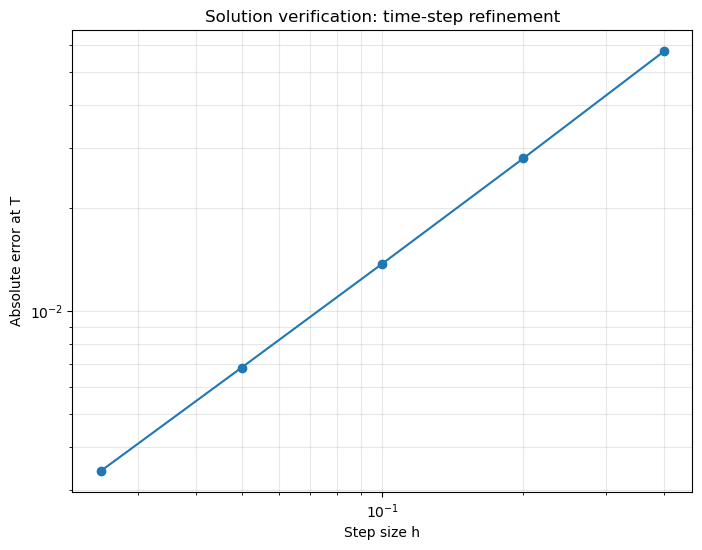

Observed orders: [1.042  1.0231 1.0118 1.006 ]


In [3]:
plt.figure(figsize=(8, 6))
plt.loglog(step_sizes, errors, marker="o")
plt.xlabel("Step size h")
plt.ylabel("Absolute error at T")
plt.title("Solution verification: time-step refinement")
plt.grid(alpha=0.3, which="both")
plt.show()

observed_orders = np.log(
    errors[:-1] / errors[1:]
) / np.log(
    step_sizes[:-1] / step_sizes[1:]
)

print("Observed orders:", np.round(observed_orders, 4))

Якщо $E(h)\approx Ch^p$, для first-order Euler очікуємо $p\approx1$. Це *verification evidence*: ми досліджуємо numerical behavior відносно mathematical problem, а не відповідність ODE реальній системі.

## 18. Валідація (validation)
Validation стосується відповідності model reality у контексті intended use:
$$
\text{model prediction}\stackrel{?}{\approx}\text{relevant reality data}.
$$
Validation не є універсальним binary label. Йдеться про degree of agreement для конкретних QoI, regime, input domain та мети використання.

## 19. Intended use
Одна model може бути достатньою для qualitative regime comparison і недостатньою для high-precision point prediction. Тому коректне питання:
> *Чи є model sufficiently accurate for intended use $U$?*

Без intended use твердження «модель валідована» методологічно неповне.

## 20. Величина інтересу (Quantity of Interest, QoI)
QoI -- output, щодо якого робиться scientific або practical inference: peak, time to threshold, final prevalence, cascade probability, recovery time тощо. Validation metric повинна бути пов'язана саме з QoI.

## 21. Calibration data і validation data
Якщо ті самі data використані і для fitting, і для оцінки agreement, маємо переважно evidence про calibration fit. Для stronger validation бажане independent або purposefully separated evidence:
$$
D=D_{cal}\cup D_{val}.
$$
Для scarce або time-dependent data split має бути обґрунтованим, а не механічним.

## 22. Validation metric
Наприклад,
$$
RMSE_{val}=
\sqrt{\frac{1}{n}\sum_i(y_i^{val}-\hat y_i)^2}.
$$
Але для threshold event важливішою може бути error у $t_{cross}$, а для risk model -- error у tail probability.

## 23. Domain of validity
Позначимо $\Omega_{val}$ -- область conditions, де model порівнювалася з relevant data. Prediction для
$$
x\in\Omega_{val}
$$
має інший epistemic status, ніж extrapolation для
$$
x\notin\Omega_{val}.
$$
Документуємо parameter/input ranges, temporal horizon, regimes, population/environment, topology class.

## 24. Interpolation і extrapolation
Interpolation -- prediction всередині supported domain. Extrapolation -- за його межами. Особливо небезпечно:
$$
\text{excellent calibration fit}+\text{structural misspecification}
\rightarrow\text{poor extrapolation}.
$$

## 25. Model discrepancy і validation
У
$$
y^{obs}=y^{model}(\hat\theta)+\delta+\varepsilon
$$
validation discrepancy може містити measurement uncertainty, parameter uncertainty, numerical error і model-form discrepancy. Тому $y^{obs}-y^{model}$ не можна автоматично називати model-form error.

## 26. Validation hierarchy
Для complex system:
$$
\text{unit}\rightarrow\text{subsystem}\rightarrow\text{coupled subsystem}\rightarrow\text{full system}.
$$
Це особливо важливо для multilevel/hybrid models: hierarchy допомагає локалізувати discrepancy.

## 27. Verification і validation не взаємозамінні

| Verification | Validation | Інтерпретація |
|---|---|---|
| добра | добра | implementation і model adequacy мають підтримку |
| добра | слабка | equations розв'язуються правильно, але model недостатньо описує reality |
| слабка | добра | agreement може компенсувати numerical/coding errors |
| слабка | слабка | credibility недостатня |

Небезпечний випадок:
$$
\text{wrong computation}+\text{parameter compensation}\approx\text{observed data}.
$$

## 28. Verification before validation
Логічний порядок:
$$
\boxed{\text{verification}\rightarrow\text{validation}}
$$
Інакше discrepancy з experimental data може походити від model-form, parameter, numerical або coding error.

## 29. Credibility як накопичувальна аргументація
Model credibility накопичується через evidence:
$$
\mathcal E=
\{E_{concept},E_{code},E_{solution},E_{cal},E_{val},E_{sens},E_{UQ}\}.
$$
Далі додамо sensitivity analysis, UQ, computational experiment design і reproducibility. Credibility -- структурована сукупність evidence, а не один scalar score.

## 30. Приклад credibility chain
Нехай QoI:
$$
Q=t:x(t)\ge x_{crit}.
$$
Перед scientific claim запитуємо:
1. чи коректний mechanism;
2. чи parameters identifiable;
3. чи code реалізує equations;
4. чи numerical solution converged;
5. чи $Q$ узгоджується з independent observations;
6. для яких regimes це перевірено;
7. наскільки $Q$ sensitive до uncertain inputs.

## 31. Verification matrix

| Компонент | Verification question | Test | Expected result |
|---|---|---|---|
| equation implementation | чи реалізовано formula правильно? | analytical benchmark | agreement |
| state update | чи зберігається invariant? | conservation check | invariant preserved |
| solver | чи converges solution? | refinement study | decreasing error |
| stochastic module | чи відтворюється distribution? | statistical test | expected moments |
| coupling | чи коректний exchange? | interface test | consistent transfer |

## 32. Validation matrix

| QoI | Intended use | Validation data | Metric | Acceptance logic |
|---|---|---|---|---|
| $Q_1$ | | | | |
| $Q_2$ | | | | |

Acceptance logic може враховувати measurement uncertainty, natural variability, required precision та competing models.

## 33. Model comparison і validation
Для competing models $M_1,\ldots,M_K$ порівнюємо не лише fit, а predictive behavior, residual structure, identifiability, complexity, robustness і domain of validity. Це повертає нас до multiple models of one object із Теми 2.

## 34. Чого V&V не дає
V&V не доводить, що model «істинна», правильна для всіх regimes або придатна для будь-якого future use.

Коректніше:
> Для визначеного intended use, QoI та domain наявні verification і validation evidence підтримують використання model із зазначеними limitations.

## 35. Зв'язок із ЛР6
Нормативна назва наступної роботи:

*«Лабораторна робота 6. Верифікація і валідація моделі, аналіз чутливості та кількісне оцінювання невизначеності».*

Логіка:
$$
\text{Calibration Specification v0.5}
\rightarrow\text{verification evidence}
\rightarrow\text{validation evidence}
\rightarrow\text{sensitivity}
\rightarrow\text{UQ}.
$$
Результатом стане *model credibility report*.

# 36. Підсумкова схема

```{mermaid}
%%{init: {'theme': 'base', 'themeVariables': {'fontSize':'18px','fontFamily':'Trebuchet MS, Verdana, Arial, sans-serif','primaryColor':'#E8F3FF','primaryBorderColor':'#3478A8','secondaryColor':'#FFF0C9','tertiaryColor':'#E7F6EC','lineColor':'#536878'}}}%%
flowchart LR
 A("Model<br/>architecture") --> B("Calibration<br/>data")
 B --> C("Identification /<br/>Calibration")
 C --> D("Code<br/>verification")
 D --> E("Solution<br/>verification")
 E --> F("Validation<br/>for intended use")
 F --> G("Domain of<br/>validity")
 G --> H("Model<br/>credibility")
```

# Контрольні запитання
1. Чим direct problem відрізняється від inverse problem?
2. Чим parametric identification відрізняється від structural identification?
3. Чим structural identification відрізняється від structural identifiability?
4. Що таке calibration?
5. Чому loss function є частиною research formulation?
6. За яких assumptions SSE має statistical interpretation?
7. Що таке practical identifiability?
8. Що означає ridge на loss surface?
9. Чому optimizer convergence не гарантує identifiability?
10. Як experimental design впливає на identifiability?
11. Що таке model discrepancy?
12. Чому calibrated parameter може стати effective parameter?
13. Що таке over-calibration?
14. Які metadata потрібно зберігати після calibration?
15. Що таке verification?
16. Що таке code verification?
17. Що таке solution verification?
18. Для чого потрібен refinement study?
19. Що таке validation?
20. Чому validation не є універсальним binary label?
21. Що таке intended use?
22. Що таке Quantity of Interest?
23. Чому calibration data бажано відрізняти від validation data?
24. Як validation metric пов'язана з QoI?
25. Що таке domain of validity?
26. Чим interpolation відрізняється від extrapolation?
27. Чому validation discrepancy не дорівнює автоматично model-form error?
28. Для чого потрібна validation hierarchy?
29. Чому verification має передувати validation?
30. Що означає model credibility?

# Висновки
1. Identification перетворює observations на information про model structure або parameters.
2. Calibration є inverse problem і залежить від model, observation operator, data та loss function.
3. Identifiability є властивістю зв'язки *model + observations*, а не optimizer.
4. Model discrepancy може бути частково поглинута calibrated parameters.
5. Малий calibration loss не є доказом scientific adequacy.
6. Verification перевіряє відповідність computational implementation математичній постановці.
7. Code verification і solution verification відповідають на різні питання.
8. Refinement study дає evidence щодо numerical error.
9. Validation оцінює agreement model із reality відносно intended use.
10. Validation має бути пов'язана з конкретною Quantity of Interest.
11. Validation evidence має обмежений domain of validity.
12. Extrapolation потребує сильнішого обґрунтування, ніж interpolation.
13. Verification і validation не взаємозамінні.
14. Model credibility формується накопиченням різних типів evidence.
15. Наступний крок -- sensitivity analysis та uncertainty quantification.

# Джерела та корисні ресурси
Використовується спільна накопичувальна бібліографічна база курсу `mmss-references.bib`.

- [SciPy documentation](https://docs.scipy.org/doc/scipy/)
- [NumPy documentation](https://numpy.org/doc/stable/)
- [Matplotlib documentation](https://matplotlib.org/stable/)
- [SALib documentation](https://salib.readthedocs.io/)

# References